# Seven-dataset uncertainty analysis

Reproducible analysis of saved predictions only. No transformer training or embedding computation.
Five metrics remain mandatory. Individual-metric sampling stability, weighted contributions and covariance,
model-pair score differences, and 100 nested coefficient reselections per held-out dataset.

Outputs: `uncertainty_results.csv`, `REPORT.md`, and five figures in `images/`.
All frequencies and covariance estimates are descriptive; no coefficient confidence intervals are claimed.


In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product, combinations
import json,re,os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,rankdata
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Markdown
ROOT=Path.cwd()
if ROOT.name=='uncertainty':ROOT=ROOT.parent
OUT=ROOT/'uncertainty';OUT.mkdir(exist_ok=True);(OUT/'images').mkdir(exist_ok=True)
METRICS=['SameMean','DffMean','SameAbsEta','DiffAbsEta','Chi2Distance']
RAW=['same_mean','diff_mean','same_abs_eta','diff_abs_eta','chi2_distance']
METHODS=['zscore','robust','rank'];N_SELECTION_REPEATS=100;SELECTION_SEED=20261026;NEAR_TOL=.01
MODEL_NAMES={'google-bert/bert-base-uncased':'BERT','allenai/scibert_scivocab_uncased':'SciBERT','nlpaueb/legal-bert-base-uncased':'LegalBERT','ahmedrachid/FinancialBERT':'FinancialBERT','Lianglab/PharmBERT-uncased':'PharmBERT','recobo/agriculture-bert-uncased':'AgricultureBERT','recobo/chemical-bert-uncased':'ChemicalBERT'}
FOLDERS={'FinancialData':'Financial','EnvData':'EnvData','ECtHR':'ECtHR','ACGNews':'ACGNews','Ohsumed':'Ohsumed','Rheology':'Rheology','arXiv':'arXiv'}
DATASETS=list(FOLDERS);MODELS=sorted(MODEL_NAMES.values());BASE=ROOT/'GridSearch/results_nested_five_required'
target=pd.read_csv(ROOT/'GridSearch/result1.csv')
source_dirs={};inputs=[];source_notes=[]
for ds,folder in FOLDERS.items():
 paths=sorted((ROOT/folder/'results').glob('uncertainty10_gpu_*'))
 complete=[p for p in paths if (p/'summary_per_run.csv').exists() and len(pd.read_csv(p/'summary_per_run.csv'))==70]
 if not complete:raise RuntimeError(f'No complete 70-row experiment: {ds}')
 path=complete[-1];source_dirs[ds]=path;d=pd.read_csv(path/'summary_per_run.csv')
 d['Dataset']=ds;d['Model']=d.model.map(MODEL_NAMES);d=d.rename(columns=dict(zip(RAW,METRICS)))
 assert d.Model.notna().all() and d.groupby('repetition').Model.nunique().eq(7).all()
 for col in METRICS:assert np.isfinite(d[col]).all()
 d=d.merge(target.loc[target.Dataset.eq(ds),['ModelName','MacroF1']],left_on='Model',right_on='ModelName',validate='many_to_one')
 inputs.append(d);source_notes.append(f'- {ds}: `{path.relative_to(ROOT)}`')
data=pd.concat(inputs,ignore_index=True);assert len(data)==490
X=np.empty((7,10,7,5));Y=np.empty((7,7))
for di,ds in enumerate(DATASETS):
 Y[di]=target.query('Dataset==@ds').set_index('ModelName').loc[MODELS].MacroF1
 for ri in range(10):X[di,ri]=data.query('Dataset==@ds and repetition==@ri+1').set_index('Model').loc[MODELS,METRICS]
records=[]
def record(kind,value,dataset='',model='',repetition='',procedure='',metric='',statistic='',model_b='',selection='',method='',source=''):
 records.append(dict(record_type=kind,dataset=dataset,model=model,model_b=model_b,repetition=repetition,procedure=procedure,selection=selection,method=method,metric=metric,statistic=statistic,value=float(value),source=source))
def standardize(x,method):
 if method=='rank':
  z=rankdata(x,axis=0,method='average')/len(x);return z-z.mean(0)
 center=x.mean(0) if method=='zscore' else np.median(x,axis=0)
 spread=x.std(0) if method=='zscore' else np.median(abs(x-center),axis=0)/.6745
 return np.divide(x-center,spread,out=np.zeros_like(x),where=~np.isclose(spread,0))
# Reusable figures saved and displayed inline.
def savefig(fig,name):
 fig.tight_layout();fig.savefig(OUT/'images'/name,dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
plt.rcParams.update({'font.size':9,'axes.spines.top':False,'axes.spines.right':False})


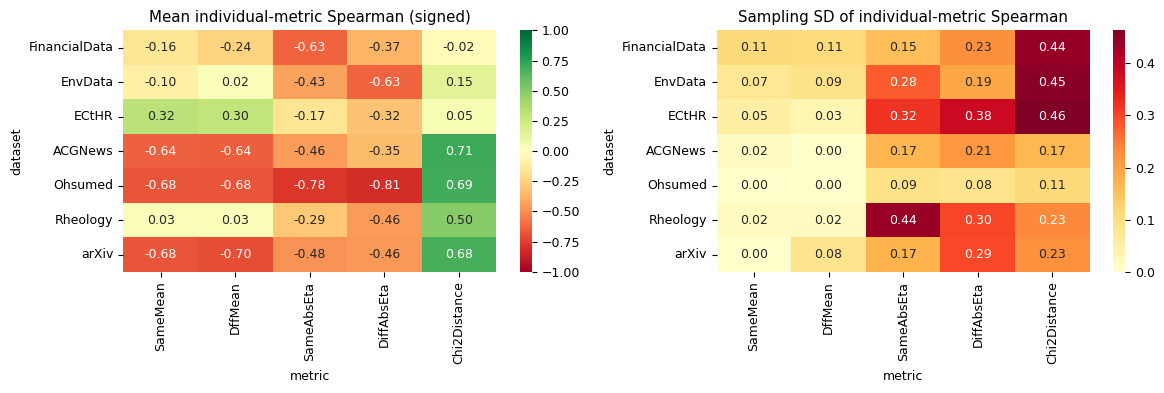

## Individual metrics: ten-round direction stability

,dataset,metric,mean,sd,minimum,maximum,positive,negative,zero,has_both_signs
0,ACGNews,Chi2Distance,0.7107,0.1653,0.4643,0.9286,10,0,0,False
1,ACGNews,DffMean,-0.6429,0.0000,-0.6429,-0.6429,0,10,0,False
2,ACGNews,DiffAbsEta,-0.3500,0.2142,-0.6429,-0.0714,0,10,0,False
3,ACGNews,SameAbsEta,-0.4607,0.1670,-0.6429,-0.1786,0,10,0,False
4,ACGNews,SameMean,-0.6357,0.0151,-0.6429,-0.6071,0,10,0,False
5,ECtHR,Chi2Distance,0.0464,0.4629,-0.4643,0.6786,4,6,0,True
6,ECtHR,DffMean,0.2964,0.0339,0.2857,0.3929,10,0,0,False
7,ECtHR,DiffAbsEta,-0.3179,0.3822,-0.8929,0.2857,3,7,0,True
8,ECtHR,SameAbsEta,-0.1679,0.3199,-0.7143,0.2143,4,6,0,True
9,ECtHR,SameMean,0.3179,0.0518,0.2857,0.3929,10,0,0,False


In [2]:
# 1. Single-metric direction and correlation stability (exactly 350 Macro F1 rhos).
single=[]
for di,ds in enumerate(DATASETS):
 for ri in range(10):
  for mi,model in enumerate(MODELS):
   for ji,metric in enumerate(METRICS):record('raw_input',X[di,ri,mi,ji],dataset=ds,model=model,repetition=ri+1,metric=metric)
   record('f1_target',Y[di,mi],dataset=ds,model=model,repetition=ri+1,metric='MacroF1')
  for ji,metric in enumerate(METRICS):
   rho=float(spearmanr(X[di,ri,:,ji],Y[di]).statistic);single.append(dict(dataset=ds,metric=metric,repetition=ri+1,rho=rho))
   record('single_metric_rho',rho,dataset=ds,repetition=ri+1,metric=metric,statistic='spearman')
single=pd.DataFrame(single);single_summary=[]
for (ds,metric),g in single.groupby(['dataset','metric']):
 a=g.rho.to_numpy();p=int(np.sum(a>1e-12));n=int(np.sum(a< -1e-12));z=10-p-n
 row=dict(dataset=ds,metric=metric,mean=a.mean(),sd=a.std(ddof=1),minimum=a.min(),maximum=a.max(),positive=p,negative=n,zero=z,has_both_signs=p>0 and n>0)
 single_summary.append(row)
 for k,v in row.items():
  if k not in ['dataset','metric']:record('single_metric_summary',v,dataset=ds,metric=metric,statistic=k)
single_summary=pd.DataFrame(single_summary);assert len(single)==350
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.heatmap(single_summary.pivot(index='dataset',columns='metric',values='mean').reindex(DATASETS)[METRICS],vmin=-1,vmax=1,cmap='RdYlGn',annot=True,fmt='.2f',ax=axes[0]);axes[0].set_title('Mean individual-metric Spearman (signed)')
sns.heatmap(single_summary.pivot(index='dataset',columns='metric',values='sd').reindex(DATASETS)[METRICS],cmap='YlOrRd',annot=True,fmt='.2f',ax=axes[1]);axes[1].set_title('Sampling SD of individual-metric Spearman')
savefig(fig,'01_single_metric_stability.png')
display(Markdown('## Individual metrics: ten-round direction stability'));display(single_summary.round(4))


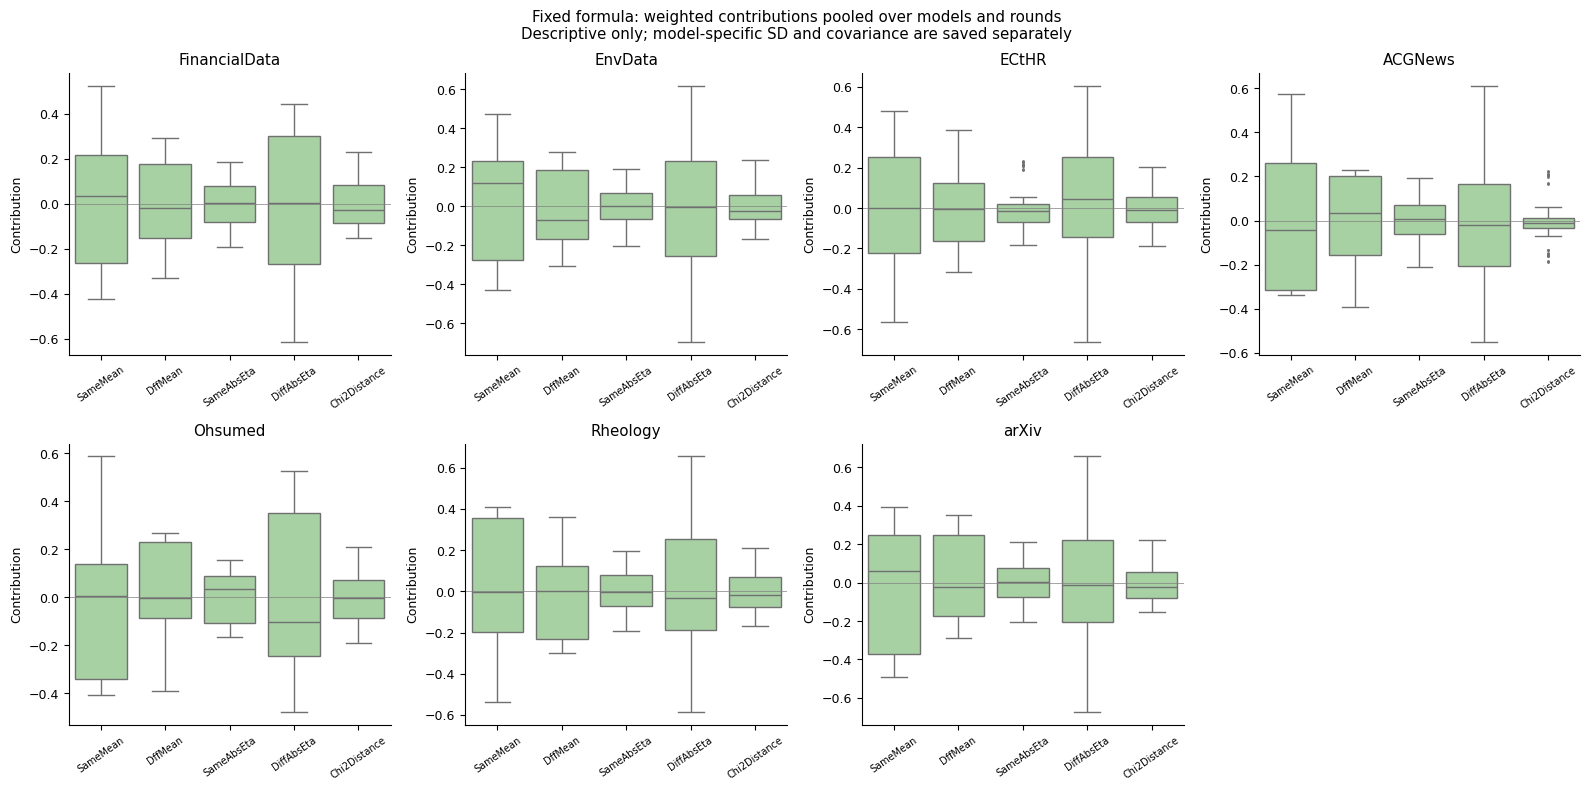

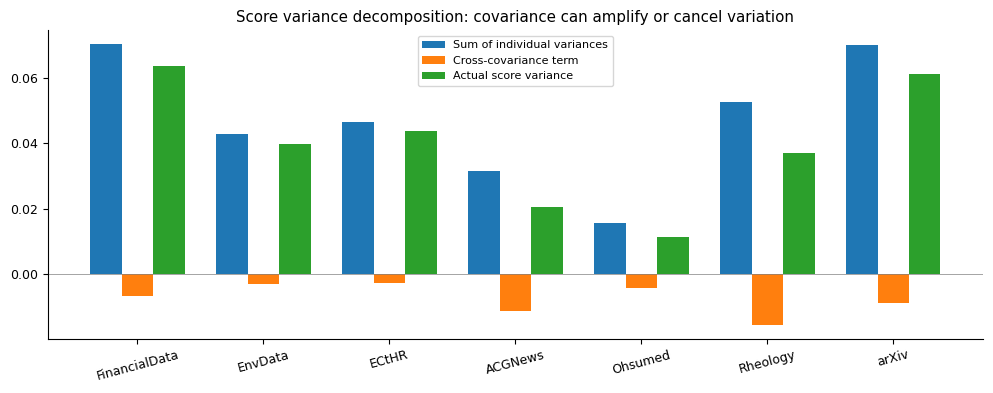

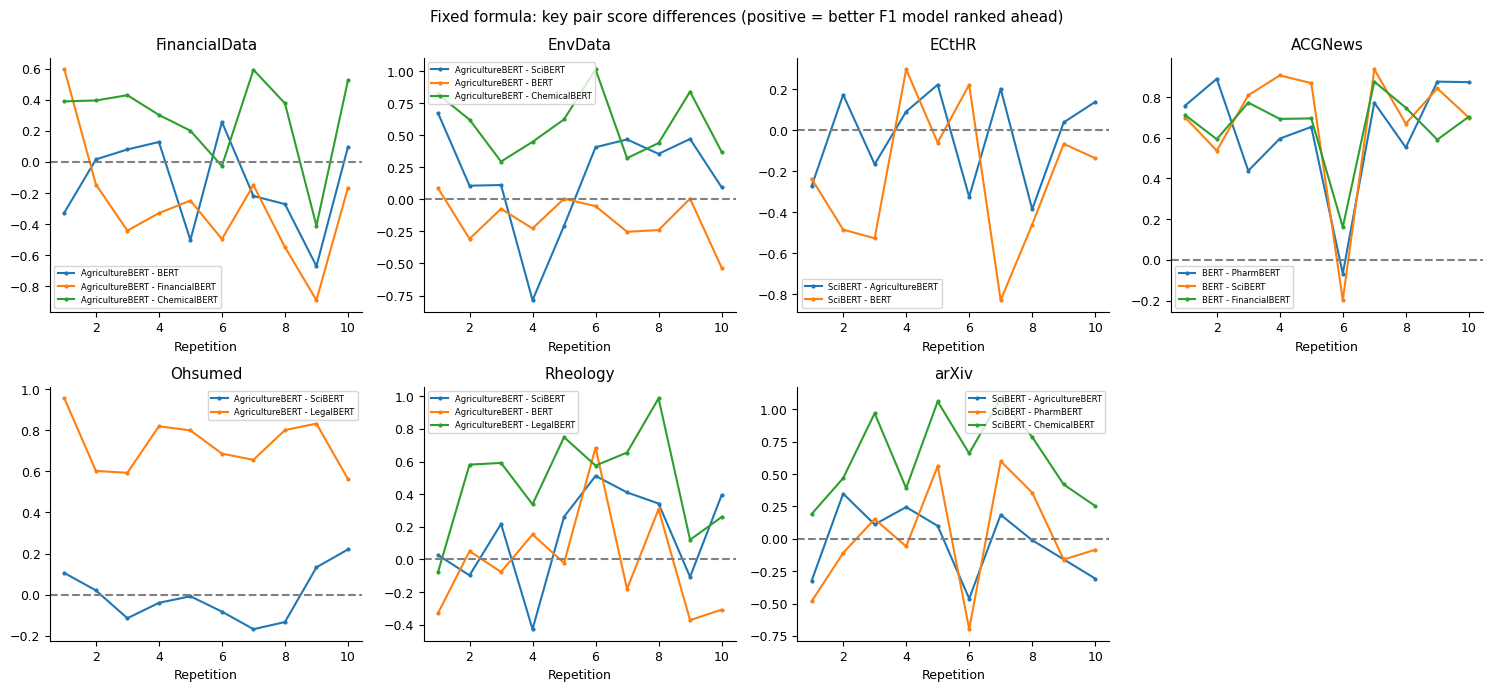

## Key model pairs

,dataset,procedure,model,model_b,f1_gap,mean,sd,minimum,maximum,wins,losses,ties,comparison
0,FinancialData,fixed,AgricultureBERT,BERT,0.0072,-0.1415,0.3031,-0.6703,0.2562,5,5,0,best_vs_second
1,FinancialData,fixed,AgricultureBERT,FinancialBERT,0.0178,-0.2819,0.3846,-0.8888,0.5945,1,9,0,best_vs_frequent_wrong
2,FinancialData,fixed,AgricultureBERT,ChemicalBERT,0.0885,0.2768,0.2963,-0.4104,0.5919,8,2,0,best_vs_worst
3,FinancialData,held_out,AgricultureBERT,BERT,0.0072,-0.4831,0.4251,-1.2490,0.1834,1,9,0,best_vs_second
4,FinancialData,held_out,AgricultureBERT,FinancialBERT,0.0178,-0.8891,1.3976,-4.2438,1.2093,1,9,0,best_vs_frequent_wrong
5,FinancialData,held_out,AgricultureBERT,ChemicalBERT,0.0885,-0.2967,0.8146,-2.1108,0.6623,4,6,0,best_vs_worst
6,EnvData,fixed,AgricultureBERT,SciBERT,0.0175,0.1694,0.4205,-0.7861,0.6731,8,2,0,best_vs_second
7,EnvData,fixed,AgricultureBERT,BERT,0.0208,-0.1586,0.1868,-0.5314,0.0874,3,7,0,best_vs_frequent_wrong
8,EnvData,fixed,AgricultureBERT,ChemicalBERT,0.0751,0.5794,0.2462,0.2947,1.0137,10,0,0,best_vs_worst
9,EnvData,held_out,AgricultureBERT,SciBERT,0.0175,0.1614,0.1313,-0.0857,0.2857,8,2,0,best_vs_second


In [3]:
# 2. Fixed historical formulas, contribution distributions, complete covariance.
final=json.load(open(BASE/'final_formula.json'));fold=pd.read_csv(BASE/'outer_fold_results.csv');coeff=pd.read_csv(BASE/'outer_coefficients.csv')
configs={};contributions={};score_arrays={};combination=[];variance_rows=[];pair_rows=[];contribution_summary=[]
for di,ds in enumerate(DATASETS):
 held=fold.query('HeldOutDataset==@ds and Procedure=="selected"').iloc[0]
 wh=coeff.query('HeldOutDataset==@ds and Procedure=="selected"').set_index('Metric').loc[METRICS].Coefficient.to_numpy()
 configs[ds]={'fixed':('zscore',np.array([final['Coefficients'][m] for m in METRICS])),'held_out':(held.Standardization,wh)}
 for proc,(method,w) in configs[ds].items():
  z=np.stack([standardize(x,method) for x in X[di]]);c=z*w;s=c.sum(2);contributions[ds,proc]=c;score_arrays[ds,proc]=s
  for ji,metric in enumerate(METRICS):record('historical_formula',w[ji],dataset=ds,procedure=proc,method=method,metric=metric,statistic='weight')
  for mi,model in enumerate(MODELS):
   for ji,metric in enumerate(METRICS):
    for ri in range(10):
     record('standardized_input',z[ri,mi,ji],dataset=ds,model=model,repetition=ri+1,procedure=proc,metric=metric)
     record('weighted_contribution',c[ri,mi,ji],dataset=ds,model=model,repetition=ri+1,procedure=proc,metric=metric)
    for kind,values in [('raw_metric',X[di,:,mi,ji]),('standardized_metric',z[:,mi,ji]),('weighted_metric',c[:,mi,ji])]:
     for stat,val in [('mean',values.mean()),('sd',values.std(ddof=1))]:record('metric_value_summary',val,dataset=ds,model=model,procedure=proc,metric=metric,statistic=kind+'_'+stat)
    contribution_summary.append(dict(dataset=ds,procedure=proc,model=model,metric=metric,sd=c[:,mi,ji].std(ddof=1)))
   cov=np.cov(z[:,mi,:],rowvar=False,ddof=1);weighted_cov=cov*np.outer(w,w)
   direct=s[:,mi].var(ddof=1);calc=float(w@cov@w);np.testing.assert_allclose(calc,direct,atol=1e-12)
   diag=float(np.trace(weighted_cov));cross=float(weighted_cov.sum()-diag)
   variance_rows.append(dict(dataset=ds,procedure=proc,model=model,variance=direct,diagonal=diag,covariance_term=cross))
   for j,metric in enumerate(METRICS):
    # Cov(C_j,S) sums to Var(S), may be negative; diagnostic, not causal importance.
    record('variance_allocation',weighted_cov[j].sum(),dataset=ds,model=model,procedure=proc,metric=metric,statistic='Cov(contribution,score)')
    for k,other in enumerate(METRICS):record('weighted_covariance',weighted_cov[j,k],dataset=ds,model=model,procedure=proc,metric=metric,statistic=other)
   for name,val in [('score_variance',direct),('sum_contribution_variances',diag),('covariance_cross_term',cross)]:record('score_variance',val,dataset=ds,model=model,procedure=proc,statistic=name)
  ranks=rankdata(-np.round(s,12),axis=1);best=np.argmax(Y[di])
  for ri in range(10):
   vals=dict(spearman=float(spearmanr(np.round(s[ri],12),Y[di]).statistic),top1=float(ranks[ri,best]==1),top3=float(ranks[ri,best]<=3),regret=float(Y[di].max()-Y[di,ranks[ri]==1].mean()))
   combination.append(dict(dataset=ds,procedure=proc,repetition=ri+1,**vals))
   for stat,val in vals.items():record('combination_run',val,dataset=ds,procedure=proc,repetition=ri+1,statistic=stat)
   for mi,model in enumerate(MODELS):
    record('model_score',s[ri,mi],dataset=ds,model=model,procedure=proc,repetition=ri+1)
    record('model_rank',ranks[ri,mi],dataset=ds,model=model,procedure=proc,repetition=ri+1)
  # All 21 model pairs; key comparisons marked below in report.
  for ai,bi in combinations(range(7),2):
   if Y[di,ai]<Y[di,bi]:ai,bi=bi,ai
   delta=s[:,ai]-s[:,bi];pos=int(np.sum(delta>1e-12));neg=int(np.sum(delta< -1e-12));ties=10-pos-neg
   pair_rows.append(dict(dataset=ds,procedure=proc,model=MODELS[ai],model_b=MODELS[bi],f1_gap=Y[di,ai]-Y[di,bi],mean=delta.mean(),sd=delta.std(ddof=1),minimum=delta.min(),maximum=delta.max(),wins=pos,losses=neg,ties=ties))
   for ri,value in enumerate(delta):record('model_pair_delta',value,dataset=ds,model=MODELS[ai],model_b=MODELS[bi],procedure=proc,repetition=ri+1)
   for stat,val in [('true_f1_gap',Y[di,ai]-Y[di,bi]),('mean',delta.mean()),('sd',delta.std(ddof=1)),('minimum',delta.min()),('maximum',delta.max()),('wins',pos),('losses',neg),('ties',ties)]:record('model_pair_summary',val,dataset=ds,model=MODELS[ai],model_b=MODELS[bi],procedure=proc,statistic=stat)
combination=pd.DataFrame(combination);pairs=pd.DataFrame(pair_rows);variance=pd.DataFrame(variance_rows)
fig,axes=plt.subplots(2,4,figsize=(16,8));contrib=pd.DataFrame(contribution_summary)
for di,ds in enumerate(DATASETS):
 ax=axes.flat[di];c=contributions[ds,'fixed'];frame=pd.DataFrame(c.reshape(-1,5),columns=METRICS).melt(var_name='Metric',value_name='Contribution')
 sns.boxplot(data=frame,x='Metric',y='Contribution',ax=ax,fliersize=1,color='#a1d99b');ax.tick_params(axis='x',rotation=35,labelsize=7);ax.set_title(ds);ax.set_xlabel('');ax.axhline(0,color='gray',lw=.5)
axes.flat[-1].axis('off');fig.suptitle('Fixed formula: weighted contributions pooled over models and rounds\nDescriptive only; model-specific SD and covariance are saved separately')
savefig(fig,'02_weighted_contributions.png')
# Visualize variance diagonal vs covariance terms, averaged over models.
fig,ax=plt.subplots(figsize=(10,4));v=variance.query('procedure=="fixed"').groupby('dataset')[['diagonal','covariance_term','variance']].mean().reindex(DATASETS)
ax.bar(np.arange(7)-.25,v.diagonal,width=.25,label='Sum of individual variances');ax.bar(np.arange(7),v.covariance_term,width=.25,label='Cross-covariance term');ax.bar(np.arange(7)+.25,v.variance,width=.25,label='Actual score variance');ax.set_xticks(range(7),DATASETS,rotation=15);ax.axhline(0,color='gray',lw=.5);ax.legend(fontsize=8);ax.set_title('Score variance decomposition: covariance can amplify or cancel variation');savefig(fig,'03_score_variance.png')
key_pairs=[]
for di,ds in enumerate(DATASETS):
 true_order=np.argsort(-Y[di]);best=MODELS[true_order[0]];second=MODELS[true_order[1]];worst=MODELS[true_order[-1]]
 ranks=rankdata(-np.round(score_arrays[ds,'fixed'],12),axis=1);first_counts=(ranks==1).sum(0);first_counts[true_order[0]]=-1;frequent_wrong=MODELS[int(np.argmax(first_counts))]
 for proc in ['fixed','held_out']:
  for why,other in [('best_vs_second',second),('best_vs_frequent_wrong',frequent_wrong),('best_vs_worst',worst)]:
   row=pairs.query('dataset==@ds and procedure==@proc and model==@best and model_b==@other').iloc[0].to_dict();row['comparison']=why;key_pairs.append(row)
key_pairs=pd.DataFrame(key_pairs)
fig,axes=plt.subplots(2,4,figsize=(15,7))
for di,ds in enumerate(DATASETS):
 ax=axes.flat[di]
 for _,p in key_pairs.query('dataset==@ds and procedure=="fixed"').drop_duplicates(['model','model_b']).iterrows():
  a=MODELS.index(p.model);b=MODELS.index(p.model_b);delta=score_arrays[ds,'fixed'][:,a]-score_arrays[ds,'fixed'][:,b]
  ax.plot(range(1,11),delta,marker='o',ms=2,label=f'{p.model} - {p.model_b}')
 ax.axhline(0,color='gray',ls='--');ax.set_title(ds);ax.legend(fontsize=6);ax.set_xlabel('Repetition')
axes.flat[-1].axis('off');fig.suptitle('Fixed formula: key pair score differences (positive = better F1 model ranked ahead)');savefig(fig,'04_key_model_pairs.png')
display(Markdown('## Key model pairs'));display(key_pairs.round(4))


Coefficient selection completed: FinancialData


Coefficient selection completed: EnvData


Coefficient selection completed: ECtHR


Coefficient selection completed: ACGNews


Coefficient selection completed: Ohsumed


Coefficient selection completed: Rheology


Coefficient selection completed: arXiv


## Repeated nested coefficient selection (not coefficient confidence intervals)

test_rho           top1           top3         near_count  \
                  mean     std   mean     std   mean     std       mean   
dataset                                                                   
ACGNews         0.4812  0.0735  0.941  0.0494  0.956  0.0499       4.64   
ECtHR           0.0461  0.0682  0.090  0.0990  0.452  0.0810       6.57   
EnvData         0.4554  0.0563  0.321  0.2249  0.868  0.0984       5.85   
FinancialData   0.3041  0.1053  0.034  0.0590  0.297  0.1417       5.28   
Ohsumed         0.8193  0.0994  0.367  0.1652  1.000  0.0000       3.82   
Rheology        0.4536  0.0606  0.191  0.0726  0.703  0.1648       5.16   
arXiv           0.5669  0.0915  0.566  0.1597  0.973  0.0633       5.55   

                      near_max_l1         near_prediction_agreement          
                  std        mean     std                      mean     std  
dataset                                                                      
ACGNews        3.2365       0.658  0.3270                    0.9807  0.0145  
ECtHR          5.0677       0.772  0.3663                    0.9688  0.0208  
EnvData        4.0586       0.720  0.3278                    0.9416  0.0420  
FinancialData  3.0187       0.720  0.2899                    0.9459  0.0355  
Ohsumed        2.7169       0.624  0.4073                    0.9524  0.0853  
Rheology       3.4487       0.646  0.3705                    0.9625  0.0281  
arXiv          3.0990       0.774  0.3199                    0.9579  0.0292

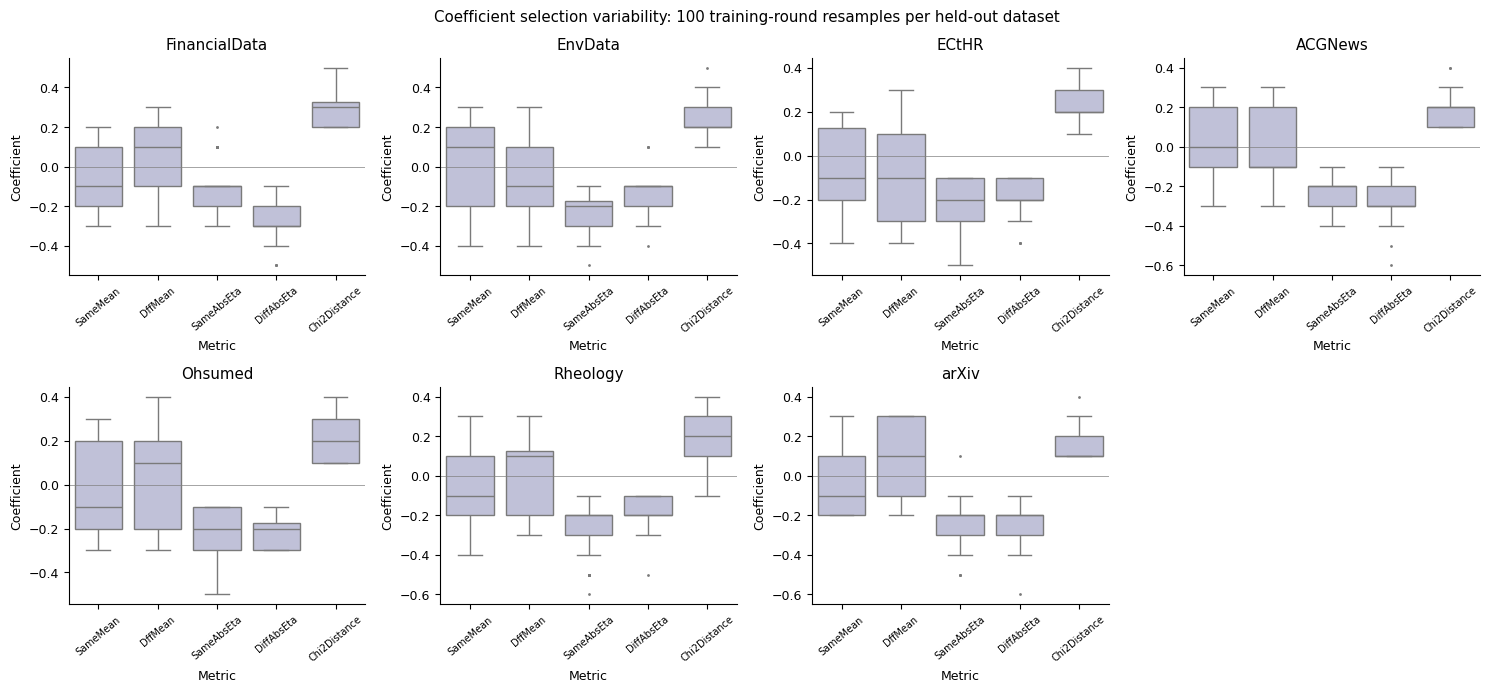

In [4]:
# 4. Repeat nested dataset-grouped coefficient selection; all five metrics compulsory.
def compositions(total,parts):
 if parts==1:yield(total,);return
 for value in range(total+1):
  for rest in compositions(total-value,parts-1):yield(value,)+rest
grid=[]
for allocation in compositions(10,5):
 if min(allocation)==0:continue
 for signs in product([-1.,1.],repeat=5):grid.append(np.array(allocation)/10*np.array(signs))
grid=np.array(grid);assert grid.shape==(4032,5) and np.allclose(abs(grid).sum(1),1)
# Compute candidate scores/ranks once; repeated searches below reuse only these arrays.
cache={};candidate_scores={};centered_true=rankdata(Y,axis=1)-4
for method in METHODS:
 rho=np.empty((7,10,len(grid)));scores_cache=np.empty((7,10,7,len(grid)))
 for di in range(7):
  for ri in range(10):
   sc=np.round(standardize(X[di,ri],method)@grid.T,12);scores_cache[di,ri]=sc
   rank=rankdata(sc,axis=0);p=rank-rank.mean(0);t=centered_true[di];den=np.sqrt((p*p).sum(0)*(t*t).sum())
   rho[di,ri]=np.divide(t@p,den,out=np.zeros(len(grid)),where=den>0)
 cache[method]=rho;candidate_scores[method]=scores_cache

def best_index(objective):
 maximum=objective.max();return int(np.flatnonzero(np.isclose(objective,maximum,atol=1e-12,rtol=0))[0])
def select_nested(train,averages):
 options=[]
 for method in METHODS:
  inner=[]
  for val in train:
   other=[i for i in train if i!=val];bi=best_index(averages[method][other].mean(0));inner.append(averages[method][val,bi])
  options.append((float(np.mean(inner)),method))
 _,method=sorted(options,key=lambda x:(-round(x[0],12),METHODS.index(x[1])))[0]
 objective=averages[method][train].mean(0);bi=best_index(objective)
 return method,bi,objective
rng=np.random.default_rng(SELECTION_SEED);selection_rows=[];near_rows=[]
for held,ds in enumerate(DATASETS):
 train=[i for i in range(7) if i!=held]
 for repeat in range(N_SELECTION_REPEATS):
  averages={m:np.zeros((7,len(grid))) for m in METHODS}
  # Only training datasets provide sampled rounds and selection objectives.
  for di in train:
   draw=rng.integers(0,10,size=10)
   for method in METHODS:averages[method][di]=cache[method][di,draw].mean(0)
  method,bi,objective=select_nested(train,averages)
  # Explicit selection-isolation check: modifying held-out objectives cannot change weights.
  if repeat==0:
   changed={m:a.copy() for m,a in averages.items()}
   for m in METHODS:changed[m][held]=rng.normal(size=len(grid))
   check_method,check_bi,_=select_nested(train,changed);assert (method,bi)==(check_method,check_bi)
  near=np.flatnonzero(objective>=objective[bi]-NEAR_TOL-1e-12)
  distance=np.abs(grid[near]-grid[bi]).sum(1)
  sc=candidate_scores[method][held,:,:,bi];rank=rankdata(-sc,axis=1);best=np.argmax(Y[held])
  # Near-optimal alternatives chosen by training objective only; test disagreement is descriptive.
  alternatives=near[np.linspace(0,len(near)-1,min(20,len(near)),dtype=int)]
  agreements=[]
  for alt in alternatives:
   alternate=candidate_scores[method][held,:,:,alt]
   arank=rankdata(-alternate,axis=1)
   agreements.append(float(np.mean([spearmanr(rank[r],arank[r]).statistic for r in range(10)])))
  result=dict(dataset=ds,selection=repeat+1,method=method,training_rho=float(objective[bi]),test_rho=float(cache[method][held,:,bi].mean()),test_rho_sd=float(cache[method][held,:,bi].std(ddof=1)),top1=float((rank[:,best]==1).mean()),top3=float((rank[:,best]<=3).mean()),near_count=len(near),near_max_l1=float(distance.max()),near_prediction_agreement=float(np.mean(agreements)))
  for ji,m in enumerate(METRICS):result[m]=grid[bi,ji];record('selected_weight',grid[bi,ji],dataset=ds,selection=repeat+1,method=method,metric=m)
  for ri in range(10):
   record('reselected_run_rho',cache[method][held,ri,bi],dataset=ds,selection=repeat+1,method=method,repetition=ri+1,statistic='spearman')
   for mi,model in enumerate(MODELS):record('reselected_model_rank',rank[ri,mi],dataset=ds,selection=repeat+1,method=method,repetition=ri+1,model=model,statistic='rank')
  selection_rows.append(result)
  for stat in ['training_rho','test_rho','test_rho_sd','top1','top3','near_count','near_max_l1','near_prediction_agreement']:record('selection_result',result[stat],dataset=ds,selection=repeat+1,method=method,statistic=stat)
  for ji,m in enumerate(METRICS):
   for stat,val in [('near_min',grid[near,ji].min()),('near_max',grid[near,ji].max())]:record('near_optimal_weight_range',val,dataset=ds,selection=repeat+1,method=method,metric=m,statistic=stat)
 print('Coefficient selection completed:',ds,flush=True)
selection=pd.DataFrame(selection_rows);assert len(selection)==700
selection_summary=selection.groupby('dataset')[['test_rho','top1','top3','near_count','near_max_l1','near_prediction_agreement']].agg(['mean','std']);display(Markdown('## Repeated nested coefficient selection (not coefficient confidence intervals)'));display(selection_summary.round(4))
fig,axes=plt.subplots(2,4,figsize=(15,7))
for di,ds in enumerate(DATASETS):
 g=selection.query('dataset==@ds');frame=g[METRICS].melt(var_name='Metric',value_name='Coefficient');sns.boxplot(data=frame,x='Metric',y='Coefficient',ax=axes.flat[di],color='#bcbddc',fliersize=1);axes.flat[di].set_title(ds);axes.flat[di].axhline(0,color='gray',lw=.5);axes.flat[di].tick_params(axis='x',rotation=40,labelsize=7)
axes.flat[-1].axis('off');fig.suptitle('Coefficient selection variability: 100 training-round resamples per held-out dataset');savefig(fig,'05_coefficient_selection.png')
for (ds,method),g in selection.groupby(['dataset','method']):
 for metric in METRICS:
  values=g[metric].to_numpy()
  for stat,val in [('mean',values.mean()),('sd',values.std(ddof=1) if len(values)>1 else 0.),('min',values.min()),('max',values.max()),('positive_count',(values>0).sum()),('negative_count',(values<0).sum()),('selection_count',len(values))]:record('coefficient_summary_within_method',val,dataset=ds,method=method,metric=metric,statistic=stat)
# Baseline: fixed model ranking chosen by mean F1 rank on training datasets only.
baseline=[]
for held,ds in enumerate(DATASETS):
 train=[i for i in range(7) if i!=held];preference=rankdata(-Y[train],axis=1).mean(0);ordering=np.lexsort((np.array(MODELS),preference));best=np.argmax(Y[held])
 result=dict(dataset=ds,rho=float(spearmanr(-preference,Y[held]).statistic),top1=float(ordering[0]==best),top3=float(best in ordering[:3]),regret=float(Y[held].max()-Y[held,ordering[0]]));baseline.append(result)
 for k,v in result.items():
  if k!='dataset':record('constant_model_baseline',v,dataset=ds,statistic=k)
baseline=pd.DataFrame(baseline)


In [5]:
# Existing F1 dispersion: folds/seeds are descriptive, not independent replicate CIs.
provenance=pd.read_csv(BASE/'f1_sources.csv');f1_disp=[]
for row in provenance.itertuples(index=False):
 path=ROOT/row.Source;ds=row.Dataset
 if path.suffix=='.csv':
  q=pd.read_csv(path).rename(columns={'test_macro_f1':'macro_f1'});unit='seed' if ds=='ECtHR' else 'fold'
  for checkpoint,g in q.groupby('model'):
   model=MODEL_NAMES[checkpoint];f1_disp.append(dict(dataset=ds,model=model,unit=unit,n=len(g),mean=g.macro_f1.mean(),sd=g.macro_f1.std()))
   for stat,val in [('mean',g.macro_f1.mean()),('sd',g.macro_f1.std()),('n',len(g))]:record('observed_f1_dispersion',val,dataset=ds,model=model,statistic=stat,source=row.Source)
  # Same fold/seed identifier matched across the true first/second models.
  di=DATASETS.index(ds);best2=np.argsort(-Y[di])[:2];reverse={v:k for k,v in MODEL_NAMES.items()}
  a=q[q.model.eq(reverse[MODELS[best2[0]]])].set_index(unit).macro_f1;b=q[q.model.eq(reverse[MODELS[best2[1]]])].set_index(unit).macro_f1;delta=(a-b).dropna()
  for stat,val in [('mean',delta.mean()),('sd',delta.std()),('wins',int((delta>0).sum())),('n',len(delta))]:record('paired_f1_top2',val,dataset=ds,model=MODELS[best2[0]],model_b=MODELS[best2[1]],statistic=stat,source=row.Source)
 else:
  notebook=json.load(open(path));texts=[]
  for cell in notebook['cells']:
   for output in cell.get('outputs',[]):
    if 'text' in output:texts.append(''.join(output['text']))
    value=output.get('data',{}).get('text/plain')
    if value:texts.append(''.join(value) if isinstance(value,list) else value)
  found=False
  for text in reversed(texts):
   if 'macro_f1_mean' not in text or 'micro_f1_mean' not in text:continue
   first,second=text.split('macro_f1_mean',1)
   ids={int(i):m for i,m in re.findall(r'^\s*(\d+)\s+(\S+/\S+)\s+[\d.]+\s+[\d.]+',first,re.M)}
   vals={int(i):(float(mean),float(sd)) for i,mean,sd,mi,mis in re.findall(r'^\s*(\d+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s*\\?\s*$',second,re.M)}
   if len(ids)!=7 or set(ids)!=set(vals):continue
   for i,checkpoint in ids.items():
    mean,sd=vals[i];model=MODEL_NAMES[checkpoint];f1_disp.append(dict(dataset=ds,model=model,unit='printed_fold_summary',n=5,mean=mean,sd=sd))
    for stat,val in [('mean',mean),('sd',sd),('n',5)]:record('observed_f1_dispersion',val,dataset=ds,model=model,statistic=stat,source=row.Source)
   found=True;break
  assert found,ds
f1_disp=pd.DataFrame(f1_disp);assert len(f1_disp)==49


In [6]:
# Final single CSV: all necessary inputs, summaries, covariance, weights and evaluations.
results=pd.DataFrame(records);assert np.isfinite(results.value).all()
results.to_csv(OUT/'uncertainty_results.csv',index=False)
verified=pd.read_csv(OUT/'uncertainty_results.csv');assert len(verified)==len(results)
# Compact self-contained Chinese report; illustrative frequencies are not probabilities.
comb_summary=combination.groupby(['dataset','procedure']).agg(mean_rho=('spearman','mean'),sd_rho=('spearman','std'),top1_count=('top1','sum'),top3_count=('top3','sum'),mean_regret=('regret','mean')).reset_index()
flip=single_summary[single_summary.has_both_signs]
pair_report=key_pairs.query('procedure=="fixed"').copy();pair_report['f1_gap_pp']=pair_report.f1_gap*100
coef_summary=selection.groupby('dataset').agg(mean_test_rho=('test_rho','mean'),selection_sd_test_rho=('test_rho','std'),mean_near_candidates=('near_count','mean'),mean_near_max_l1=('near_max_l1','mean'),mean_near_prediction_agreement=('near_prediction_agreement','mean'))
method_frequency=pd.crosstab(selection.dataset,selection.method).reindex(DATASETS).fillna(0).astype(int)
report='''# Uncertainty test：七数据集误差与选择稳定性分析

日期：2026-10-26。仅从已有结果抽取，没有重新训练语言模型、重新计算 embedding 或修改原实验。主目标是解释采样敏感性和系统性错误；系数重选为单独的探索实验，不替换原公式。

## 实验定义

7 数据集 × 10 文档样本 × 7 模型。五个指标全部保留。真实 Macro F1 固定来自 GridSearch/result1.csv。逐轮标准化严格沿用原 zscore/robust/rank 规则；固定共享公式与历史留出公式分别分析。原始指标有符号相关性保留，不逐轮取绝对值。

唯一数值文件 uncertainty_results.csv 使用长表：record_type、dataset、model、model_b、repetition、procedure、selection、method、metric、statistic、value、source。不同 record_type 不能当独立样本直接混合求均值。Notebook uncertainty_analysis.ipynb 是必要的可复现分析代码，不是临时 agent 操作脚本。

## 1. 单指标：350 个逐轮 Spearman

这里的相关系数回答关联方向；十轮间波动才描述采样敏感性。方向翻转指十轮内既有正也有负，零单独计数。

'''+single_summary.round(4).to_markdown(index=False)+f'\n\n共有 **{len(flip)}/35 个数据集—指标组合**出现正负方向翻转。单纯负相关若方向稳定，可能适合负权重；不能直接称为指标无效。\n\n![单指标](images/01_single_metric_stability.png)\n'
report+='''
## 2. 指标波动如何传入总分

CSV 保存原始值、标准化值、加权贡献的十轮均值/SD，每模型每轮分数和排名，以及完整 5×5 加权协方差矩阵。验证全部 98 个数据集—模型—公式的 Var(S)=wᵀΣw 恒等式通过。

Cov(C_j,S) 作为可加的方差诊断，和为总方差，但可能为负；不是因果重要性。对角线之和与总方差的差就是交叉协方差项。十轮协方差仅初步估计。

贡献箱线图合并了模型与轮次，仅用于总览；个体解释应在 CSV 筛选具体模型查看，不能把跨模型差异当抽样不确定性。

![贡献](images/02_weighted_contributions.png)
![方差](images/03_score_variance.png)

## 3. 关键模型对

A 总是已有平均真实 F1 更高的模型；正 ΔS 表示预测方向正确。frequent_wrong 对象由这次固定公式的十轮结果识别，是事后诊断，不是预注册检验。所有 21 对也保存，避免只选择有利案例。下面使用固定共享公式。

'''+pair_report[['dataset','comparison','model','model_b','f1_gap_pp','mean','sd','minimum','maximum','wins','losses','ties']].round(4).to_markdown(index=False)+'''

分数差跨零表示顺序采样敏感；十轮始终排反表示观测到稳定错误，不能据十次推断未来必然排反。8/10 是频率，不是“80% 概率 A 更好”。F1 非常接近时应同时看实际 regret。

![模型对](images/04_key_model_pairs.png)

## 4. 重新选择权重：100 次/留出任务，共 700 次

保留原 4,032 个候选（五项非零、0.1 步长、绝对权重和为 1）。每次仅在其余六数据集内部，对每数据集的十个已有轮次有放回抽十次；先对轮次平均候选 Spearman，再对任务等权平均。内层留出训练数据集，选择 zscore/robust/rank；然后用全部六任务选权重。并列沿用原确定性规则。

外层留出的十轮仅在配置确定后评价；改写外层目标的隔离检查对七任务通过。未用外层表现选惩罚强度或筛选权重。选择 seed=20261026。

这只反映已观察十轮内的系数选择敏感性；不是回归系数 CI，未覆盖所有可能数据扰动，也没有解决七任务已被反复查看的问题。

近优集合预先定义为所选标准化下训练平均 Spearman 与最佳差不超过 0.01。记录近优权重数、距所选权重的最大 L1 距离、各权重范围；最多20个按候选索引均匀取样的近优解，在外层十轮上比较其排名与所选解的 Spearman。后者仅用于描述，不能用来反选模型。

'''+coef_summary.round(4).to_markdown()+ '\n\n标准化选择次数（每行100）：\n\n'+method_frequency.to_markdown()+'''

![权重](images/05_coefficient_selection.png)

## 5. 参照：不使用五指标的固定模型偏好基线

只用外层训练任务的平均真实排名确定固定模型优先顺序，在目标任务上评价。它是比较基线，不是取代五指标主实验。

'''+baseline.round(4).to_markdown(index=False)+'''

## 6. 真实 F1 自身波动

直接提取已有每折或 seed 的 Macro F1。Financial/Env 只有可靠打印均值与 SD，保留六位精度，不虚构配对折值；其他任务额外保存实际第一与第二模型按同 fold/seed 配对的差值均值、SD、胜出次数。

'''+f1_disp.round(6).to_markdown(index=False)+'''

折/seed 数很少，交叉验证折也并非独立重复训练任务；配对差值只是描述，不能直接称作模型真实优劣的95%置信区间。F1 的这些波动尚未传播进组合选择或这次 Spearman。

## 已知限制与下一步

样本共享文档对，内部 bootstrap 不是文档级独立置信区间；七十重复不是独立任务。数据预处理长度分组规则未被统一，本分析保持原实验。不同模型的训练 F1 来源及折/seed 数不同。原多标签按完整标签集配对分组的重采样及余数分配规则未改变。

下一步可以预先确定主要目标（Spearman、Top-k 或 regret），用当前分析定位失败机制，再设计新版本方法；不得据这次外层结果反复优化并称其为独立测试。需要新任务外部验证。

## 输入来源

'''+ '\n'.join(source_notes)+'\n\n真实 F1 与权重来源：GridSearch/result1.csv；GridSearch/results_nested_five_required/。\n'
# Interpret observations without claiming independent final-test improvement.
wrong=pairs.query('procedure=="fixed" and losses==10')
report+='\n## 结果解释与优先关注\n\n- 35个数据集—指标组合中，9个出现正负方向翻转，集中在 ECtHR、EnvData、Financial 的 χ² 以及部分 η 指标；完整明细见第一节。\n- 原固定公式存在十轮始终排反的模型对：\n\n'+wrong[['dataset','model','model_b','f1_gap','mean','sd','wins','losses']].round(4).to_markdown(index=False)
report+='\n\n这些是系统性偏差的观测证据，增加相同机制下的采样次数不保证能修正。\n\n'
report+=f"- 训练任务平均排名的固定偏好基线在七任务的平均 Spearman 为 {baseline.rho.mean():.3f}，Top1 命中 {int(baseline.top1.sum())}/7，Top3 含最佳 {int(baseline.top3.sum())}/7。当前复杂组合必须认真与该基线比较，不能只展示自身正相关。此基线仍来自相同七个已探索任务，不是外部最终测试。\n"
report+='- 部分近优权重的 L1 差异较大，但外层排名与所选解的平均相关性仍较高；这支持“系数不唯一不一定等于预测完全不稳定”，不支持将权重大小解释为因果重要性。\n- 权重图混合了不同标准化选择，数值尺度未必可直接比较；CSV 另存 method 分层的均值、SD、符号次数。选择波动的SD与文档采样波动SD是两层不同统计量。\n- 新权重重选的外层均值不能直接宣称比旧方法有显著进步：训练输入与程序已改变，且外层任务已被反复查看，需预设后续实验和新数据验证。\n'
(OUT/'REPORT.md').write_text(report,encoding='utf-8')
display(Markdown('## Completed'));display(comb_summary.round(4));print('All analyses saved:',OUT,'records:',len(results))
print('SIGN_FLIPS',len(flip));print(coef_summary.round(4).to_string())


/tmp/ipykernel_30534/3984587192.py:4: DtypeWarning: Columns (0: procedure, 1: source) have mixed types. Specify dtype option on import or set low_memory=False.
  verified=pd.read_csv(OUT/'uncertainty_results.csv');assert len(verified)==len(results)


## Completed

,dataset,procedure,mean_rho,sd_rho,top1_count,top3_count,mean_regret
0,ACGNews,fixed,0.5107,0.1487,9.0,9.0,0.0005
1,ACGNews,held_out,0.4786,0.1767,9.0,10.0,0.0005
2,ECtHR,fixed,0.0429,0.2693,0.0,5.0,0.0384
3,ECtHR,held_out,0.0429,0.2693,0.0,5.0,0.0384
4,EnvData,fixed,0.5464,0.1717,2.0,9.0,0.0174
5,EnvData,held_out,0.4105,0.2212,0.0,8.0,0.0219
6,FinancialData,fixed,0.2214,0.2939,0.0,4.0,0.0148
7,FinancialData,held_out,-0.1000,0.4665,0.0,1.0,0.0170
8,Ohsumed,fixed,0.8607,0.0662,1.0,10.0,0.0195
9,Ohsumed,held_out,0.6964,0.3110,3.0,9.0,0.0221


All analyses saved: /home/amyliu/Desktop/GR/uncertainty records: 100456
SIGN_FLIPS 9
               mean_test_rho  selection_sd_test_rho  mean_near_candidates  mean_near_max_l1  mean_near_prediction_agreement
dataset                                                                                                                    
ACGNews               0.4812                 0.0735                  4.64             0.658                          0.9807
ECtHR                 0.0461                 0.0682                  6.57             0.772                          0.9688
EnvData               0.4554                 0.0563                  5.85             0.720                          0.9416
FinancialData         0.3041                 0.1053                  5.28             0.720                          0.9459
Ohsumed               0.8193                 0.0994                  3.82             0.624                          0.9524
Rheology              0.4536                 0.